# EKF 21 · Correcciones de CO₂ sin umbral de flujo

Se compara la regla original de 0,05 g/L/h con una variante que admite cualquier flujo en dos ventanas consecutivas válidas de 30 min. S utiliza el EKF 20 con S 17_2 y el ajuste de Q de crecimiento. G/F utiliza el EKF 18 con G/F 16_2 y el reparto de YAN activo. Cada comparación conserva sus ecuaciones, rampa, matriz Q, R, calibración y entradas. Solo se asimila CO₂.

La comparación principal usa ventanas observadas. En G/F se repite además la comparación con la ventana interpolada del EKF 18 para LAB022–024. En gráficas y métricas principales esa ventana conserva el hueco original. Se mantiene el orden LAB019–021, LAB016–018 y LAB022–024.

Para el modelo S, \(S_0 = 2{,}5(\rho_0-1000)\), con densidad y azúcar en g/L. Los puntos de validación de azúcar se obtienen con la misma conversión. Se muestran los valores convertidos negativos cuando los hay. Las mediciones de densidad posteriores a la inicial se usan para comparar la trayectoria.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src/wine_fermentation").is_dir())
EKF = ROOT / "notebooks/EKF"
ORDER = ("LAB019", "LAB020", "LAB021", "LAB016", "LAB017", "LAB018",
         "LAB022", "LAB023", "LAB024")
FOCUS = ("LAB023", "LAB024")
WITH_THRESHOLD = "Con umbral"
WITHOUT_THRESHOLD = "Sin umbral"
RULES = (WITH_THRESHOLD, WITHOUT_THRESHOLD)
STYLES = {WITH_THRESHOLD: dict(c="#D55E00", ls="--", zorder=3),
          WITHOUT_THRESHOLD: dict(c="#0072B2", zorder=2)}


def load_reference(number, cells):
    path, = EKF.glob(f"{number}_*.source.ipynb")
    notebook = nbformat.read(path, 4)
    namespace = {"__name__": f"ekf_{number}", "display": lambda *_: None}
    for index in cells:
        source = "\n".join(line for line in notebook.cells[index].source.splitlines()
                           if not line.startswith("%matplotlib"))
        exec(compile(source, f"{path.name} :: cell {index}", "exec"), namespace)
    return namespace


def window_rule(valid):
    valid = np.asarray(valid, dtype=bool)
    return valid & np.r_[False, valid[:-1]]


def validate_base_rule(valid, measured, original):
    np.testing.assert_array_equal(window_rule(valid & (measured >= .05)), original)
    assert np.all(~original | window_rule(valid))


## Modelo S · configuración del EKF 20

In [2]:
single = load_reference(20, (1, 3, 5))
single_model = single["models"]["Q ajustado"]
def sugar_from_density(density_g_l):
    return 2.5 * (density_g_l - 1000.)


historical_density = single["v"].density.rename(
    columns={"t_h": "time", "density_g_l": "density"})
recent_density = single["prepared"]["offline"].rename(
    columns={"hours": "time", "Densidad_g_L": "density"})
density_points = {}
density_audit = []
for lab in ORDER:
    inputs = single["data"][lab]
    source = historical_density if lab in single["historical"] else recent_density
    rows = source.loc[source.lab.eq(lab), ["sample", "time", "density"]].dropna(
        subset=["time", "density"]).sort_values("time")
    initial_mask = rows.time.eq(0.) if lab in single["historical"] else rows["sample"].eq("01")
    assert initial_mask.sum() == 1, lab
    initial_density = float(rows.loc[initial_mask, "density"].iloc[0])
    density_s0 = sugar_from_density(initial_density)
    assert density_s0 > 0. and rows.loc[initial_mask, "time"].iloc[0] <= inputs["grid"][0]
    validation = rows.loc[~initial_mask & rows.time.between(inputs["grid"][0], inputs["grid"][-1])]
    assert not validation.empty, lab
    density_points[lab] = dict(
        initial_time=inputs["grid"][0], initial_sugar=density_s0,
        times=validation.time.to_numpy(), sugar=sugar_from_density(validation.density.to_numpy()))
    initial = inputs["initial"].copy()
    previous_s0 = initial[2]
    initial[2] = density_s0
    np.testing.assert_array_equal(np.delete(initial, 2), np.delete(inputs["initial"], 2))
    single["data"][lab] = {**inputs, "initial": initial}
    density_audit.append({"LAB": lab, "Densidad inicial [g/L]": initial_density,
                          "S inicial anterior [g/L]": previous_s0,
                          "S inicial por densidad [g/L]": density_s0,
                          "Muestras de validación": len(validation)})
density_audit = pd.DataFrame(density_audit).set_index("LAB")
display(density_audit.round(3))

single_results = {}

for lab in ORDER:
    inputs = single["data"][lab]
    sensor = inputs["sensor"]
    valid = sensor.valid.to_numpy()
    original = sensor["update"].to_numpy()
    validate_base_rule(valid, sensor.measured.to_numpy(), original)
    for label in RULES:
        updates = original if label == WITH_THRESHOLD else window_rule(valid)
        run_inputs = {**inputs, "sensor": sensor.assign(update=updates)}
        states, readings = single["replay"](run_inputs, single_model)
        single_results[lab, label] = (states, readings)
        print("S", lab, label, flush=True)
    np.testing.assert_array_equal(single_results[lab, WITH_THRESHOLD][0][:, 1],
                                  single_results[lab, WITHOUT_THRESHOLD][0][:, 1])


        Densidad inicial [g/L]  S inicial anterior [g/L]  S inicial por densidad [g/L]  Muestras de validación
LAB                                                                                                           
LAB019                  1067.6                    158.16                        169.00                      11
LAB020                  1068.5                    157.46                        171.25                      11
LAB021                  1066.8                    161.23                        167.00                      11
LAB016                  1069.0                    172.50                        172.50                       8
LAB017                  1069.0                    172.50                        172.50                       8
LAB018                  1069.0                    172.50                        172.50                       8
LAB022                  1068.6                    150.03                        171.50                       5
L

,Densidad inicial [g/L],S inicial anterior [g/L],S inicial por densidad [g/L],Muestras de validación
LAB,,,,
LAB019,1067.6,158.16,169.00,11
LAB020,1068.5,157.46,171.25,11
LAB021,1066.8,161.23,167.00,11
LAB016,1069.0,172.50,172.50,8
LAB017,1069.0,172.50,172.50,8
LAB018,1069.0,172.50,172.50,8
LAB022,1068.6,150.03,171.50,5
LAB023,1068.2,150.92,170.50,5
LAB024,1068.0,149.75,170.00,5


## Modelo G/F · configuración del EKF 18 con reparto de YAN

In [3]:
dual = load_reference(18, (2, 4, 5, 7, 8))
dual_results, dual_interpolated = {}, {}
for lab in ORDER:
    cases = {name: dual["data"][lab][name]
             for name in ("Sin rellenar", "Interpolado")} if lab in dual["labs"] else {
                 "Observado": dual["DATA"][lab]}
    for case, inputs in cases.items():
        grid = inputs["grid"]
        on_half_hour = (grid > 0.) & np.isclose(grid * 2, np.round(grid * 2), rtol=0, atol=1e-8)
        valid = inputs["valid"][on_half_hour]
        original = inputs["update"][on_half_hour]
        validate_base_rule(valid, inputs["y"][on_half_hour], original)
        new_rule = np.zeros_like(inputs["update"])
        new_rule[on_half_hour] = window_rule(valid)
        assert not np.any(inputs["update"] & ~new_rule)
        runs = dual_interpolated if case == "Interpolado" else dual_results
        for label in RULES:
            update = inputs["update"] if label == WITH_THRESHOLD else new_rule
            outputs = dual["replay"]({**inputs, "update": update}, partition_yan=True)
            runs[lab, label] = (inputs, outputs)
            print("G/F", lab, case, label, flush=True)


G/F · 18 corridas observadas y 6 con interpolación


## Variables y observaciones

In [4]:
SYMBOLS = {
    "X": ("Biomasa viable", "g/L"), "N": ("YAN", "mg N/L"),
    "S": ("Azúcar total S", "g/L"), "GF": ("G+F", "g/L"),
    "G": ("Glucosa", "g/L"), "F": ("Fructosa", "g/L"),
    "E": ("Etanol", "g/L"), "CO2": ("Flujo de CO₂", "g/L/h"),
}
VARIABLES = {"S": ("X", "N", "S", "E", "CO2"),
             "G/F": ("X", "N", "G", "F", "GF", "E", "CO2")}
RECENT_COLUMNS = {"N": "YAN for plot", "GF": "GLU-FRU-320",
                  "G": "GLUCOSE-320", "F": "Fructose (derived)"}


def normalize_single(lab, label):
    states, readings = single_results[lab, label]
    inputs = single["data"][lab]
    x, n, s, e = (states[:, 0, :4] * single["SCALE_EKF"][:4]).T
    return dict(time=inputs["grid"], pulse=list(inputs["pulses"]),
                states={"X": x, "N": n * 1000., "S": s, "E": e},
                gas=readings.rename(columns={"t_h": "time"}))


def normalize_dual(lab, label, *, interpolated=False):
    runs = dual_interpolated if interpolated else dual_results
    inputs, ((states, _, diag), yan, _, _) = runs[lab, label]
    grid = inputs["grid"]
    mask = np.isfinite(diag[:, 0])
    x, n, g, f, e = states[:, :5].T
    gas = pd.DataFrame(dict(time=grid[mask], measured=inputs["y"][mask],
                            valid=inputs["valid"][mask], forecast=diag[mask, 0],
                            update=diag[mask, 5] == 1, delta_yan_mg_L=yan[mask, 1]))
    return dict(time=grid, pulse=grid[inputs["doses"] > 0],
                states={"X": x, "N": n * 1000., "G": g, "F": f, "GF": g + f, "E": e},
                gas=gas)


TRAJECTORIES = {(model, lab, label): normalize(lab, label)
                for model, normalize in (("S", normalize_single), ("G/F", normalize_dual))
                for lab in ORDER for label in RULES}


def lab_samples(model, lab, variable):
    if variable == "S":
        density = density_points[lab]
        return density["times"], density["sugar"]
    chemical_state = variable
    if model == "S" and variable == "X":
        samples = single["scoring_samples"][lab]
        return samples.t_h, samples.X_viable_g_l
    if lab in dual["labs"]:
        if variable == "X":
            samples = dual["biomass"]
            samples = samples.loc[samples.lab.eq(lab) & samples["sample"].ne("01")]
            return samples.hours, samples.X_g_L
        if chemical_state not in RECENT_COLUMNS:
            return [], []
        samples = single["holdout_chemistry"] if model == "S" else dual["chemistry"]
        name = RECENT_COLUMNS[chemical_state]
        samples = samples.loc[samples.lab.eq(lab) & samples["sample"].ne("01")].dropna(subset=[name])
        return samples.hours, samples[name]
    scale = 1000. if variable == "N" else 1.
    if model == "S":
        samples = single["chemical_observations"](single["v"].chem, lab, chemical_state)
        samples = samples.loc[samples.t_h.gt(0.) & samples.t_h.le(single["data"][lab]["grid"][-1])]
        return samples.t_h, scale * samples[single["CHEMICAL_COLUMNS"][chemical_state]]
    name = dual["core"].CHEM_COLS.get(chemical_state)
    if name is None or name not in dual["CHEM"]:
        return [], []
    samples = dual["CHEM"]
    samples = samples.loc[samples.lab.eq(lab) & samples.t_h.gt(0.) &
                          samples.t_h.le(dual["DATA"][lab]["horizon"])].dropna(subset=[name])
    if chemical_state == "GF":
        samples = samples.loc[~samples.GF_zero_substitution.astype(str).str.lower().eq("true")]
    return samples.t_h, scale * samples[name]


## Inicio de corrección y cola de CO₂

El salto es la diferencia de YAN justo antes y después de una corrección, sin incluir la propagación ni el pulso. Se informa la primera corrección, la primera con un cambio de al menos 1 mg N/L y la mayor corrección individual de las primeras 40 h. Se evalúa el pronóstico de CO₂ previo a la corrección en ventanas observadas válidas desde 1 h, con una métrica adicional desde 130 h. El último cruce de 0,05 se usa como métrica de duración en ambas corridas.

In [5]:
def metrics_row(run, observed):
    time, states = run["time"], run["states"]
    gas = run["gas"]
    np.testing.assert_array_equal(gas.time.to_numpy(), observed.time.to_numpy())
    first = gas.loc[gas["update"]].iloc[0]
    effective = gas.loc[gas["update"] & gas.delta_yan_mg_L.abs().ge(1.)]
    early = gas.loc[gas["update"] & gas.time.le(40.)]
    peak = early.loc[early.delta_yan_mg_L.abs().idxmax()] if len(early) else None
    valid = observed.valid & observed.time.ge(1.)
    tail = valid & observed.time.ge(130.)
    error = gas.forecast - observed.measured
    start_tail = np.flatnonzero((time > max(run["pulse"])) & (states["N"] <= 1.))
    return {
        "Primera corrección [h]": first.time,
        "ΔYAN primera corrección [mg N/L]": first.delta_yan_mg_L,
        "Primer abs(ΔYAN) ≥1 [h]": effective.time.min(),
        "Mayor ΔYAN hasta 40 h [mg N/L]": peak.delta_yan_mg_L if peak is not None else np.nan,
        "Hora del mayor salto [h]": peak.time if peak is not None else np.nan,
        "Correcciones": int(gas["update"].sum()),
        "RMSE CO₂ [g/L/h]": np.sqrt(np.mean(error[valid] ** 2)),
        "RMSE CO₂ desde 130 h [g/L/h]": np.sqrt(np.mean(error[tail] ** 2)),
        "Ventanas de cola": int(tail.sum()),
        "Última hora CO₂ pronosticado ≥0,05": gas.loc[valid & gas.forecast.ge(.05), "time"].max(),
        "Última hora CO₂ medido ≥0,05": observed.loc[valid & observed.measured.ge(.05), "time"].max(),
        "Máximo YAN tras llegar a ≤1 pospulso [mg N/L]":
            states["N"][start_tail[0]:].max() if len(start_tail) else np.nan,
    }


rows = []
for model in VARIABLES:
    for lab in ORDER:
        observed = TRAJECTORIES[model, lab, WITH_THRESHOLD]["gas"]
        for rule in RULES:
            run = TRAJECTORIES[model, lab, rule]
            rows.append(dict(Modelo=model, LAB=lab, Regla=rule, **metrics_row(run, observed)))
metrics = pd.DataFrame(rows).set_index(["Modelo", "LAB", "Regla"])
focus = metrics.loc[(slice(None), list(FOCUS), slice(None)), :]
display(focus.round(4))
print(focus.round(4).to_string())
display(metrics.round(4))

sensitivity = []
for lab in dual["labs"]:
    observed = TRAJECTORIES["G/F", lab, WITH_THRESHOLD]["gas"]
    for rule in RULES:
        run = normalize_dual(lab, rule, interpolated=True)
        sensitivity.append(dict(LAB=lab, Regla=rule, **metrics_row(run, observed)))
print("G/F con la ventana interpolada del EKF 18; puntuación sobre las ventanas observadas.")
display(pd.DataFrame(sensitivity).set_index(["LAB", "Regla"]).round(4))


                          Primera corrección [h]  ΔYAN primera corrección [mg N/L]  Primer abs(ΔYAN) ≥1 [h]  Mayor ΔYAN hasta 40 h [mg N/L]  Hora del mayor salto [h]  Correcciones  RMSE CO₂ [g/L/h]  RMSE CO₂ desde 130 h [g/L/h]  Ventanas de cola  Última hora CO₂ pronosticado ≥0,05  Última hora CO₂ medido ≥0,05  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
Modelo LAB    Regla                                                                                                                                                                                                                                                                                                                                                   
S      LAB023 Con umbral                    23.0                           31.4187                     23.0                         31.4187                      23.0           294            0.1026                        0.0809               121                               129.5 

Primera corrección [h]  ...  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
Modelo LAB    Regla                               ...                                               
S      LAB023 Con umbral                    23.0  ...                                         0.9320
              Sin umbral                     1.5  ...                                         0.9919
G/F    LAB023 Con umbral                    23.0  ...                                         0.9248
              Sin umbral                     1.0  ...                                         0.8676
S      LAB024 Con umbral                    23.0  ...                                         0.8357
              Sin umbral                     1.5  ...                                         0.8183
G/F    LAB024 Con umbral                    23.0  ...                                         0.9387
              Sin umbral                     1.0  ...                                         0.9763

[8 rows x 12 columns]

Primera corrección [h]  ...  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
Modelo LAB    Regla                               ...                                               
S      LAB019 Con umbral                    16.5  ...                                         0.8964
              Sin umbral                     1.0  ...                                         0.9570
       LAB020 Con umbral                    30.5  ...                                         0.9427
              Sin umbral                     1.0  ...                                         0.9302
       LAB021 Con umbral                    16.0  ...                                         0.7829
              Sin umbral                     1.0  ...                                         0.8251
       LAB016 Con umbral                    10.0  ...                                         0.9370
              Sin umbral                     1.0  ...                                         0.9997
       LAB017 Con umbral                    17.5  ...                                         0.8003
              Sin umbral                     1.0  ...                                         0.9868
       LAB018 Con umbral                    12.0  ...                                         0.8677
              Sin umbral                     1.0  ...                                         0.9332
       LAB022 Con umbral                    64.0  ...                                         0.8131
              Sin umbral                     1.5  ...                                         0.8366
       LAB023 Con umbral                    23.0  ...                                         0.9320
              Sin umbral                     1.5  ...                                         0.9919
       LAB024 Con umbral                    23.0  ...                                         0.8357
              Sin umbral                     1.5  ...                                         0.8183
G/F    LAB019 Con umbral                    16.5  ...                                         0.9753
              Sin umbral                     1.0  ...                                         0.9884
       LAB020 Con umbral                    30.5  ...                                         0.9926
              Sin umbral                     1.0  ...                                         0.9349
       LAB021 Con umbral                    16.0  ...                                         0.8559
              Sin umbral                     1.0  ...                                         0.8599
       LAB016 Con umbral                    10.0  ...                                         0.9687
              Sin umbral                     1.0  ...                                         0.9070
       LAB017 Con umbral                    17.5  ...                                         0.9481
              Sin umbral                     1.0  ...                                         0.9430
       LAB018 Con umbral                    12.0  ...                                         0.9654
              Sin umbral                     1.0  ...                                         0.8482
       LAB022 Con umbral                    64.0  ...                                         0.9318
              Sin umbral                     1.0  ...                                         0.9009
       LAB023 Con umbral                    23.0  ...                                         0.9248
              Sin umbral                     1.0  ...                                         0.8676
       LAB024 Con umbral                    23.0  ...                                         0.9387
              Sin umbral                     1.0  ...                                         0.9763

[36 rows x 12 columns]

Primera corrección [h]  ...  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
LAB    Regla                               ...                                               
LAB022 Con umbral                    64.0  ...                                         0.9318
       Sin umbral                     1.0  ...                                         0.9009
LAB023 Con umbral                    22.5  ...                                         0.9363
       Sin umbral                     1.0  ...                                         0.9836
LAB024 Con umbral                    22.5  ...                                         0.9426
       Sin umbral                     1.0  ...                                         0.9590

[6 rows x 12 columns]

## Curvas de los nueve lotes

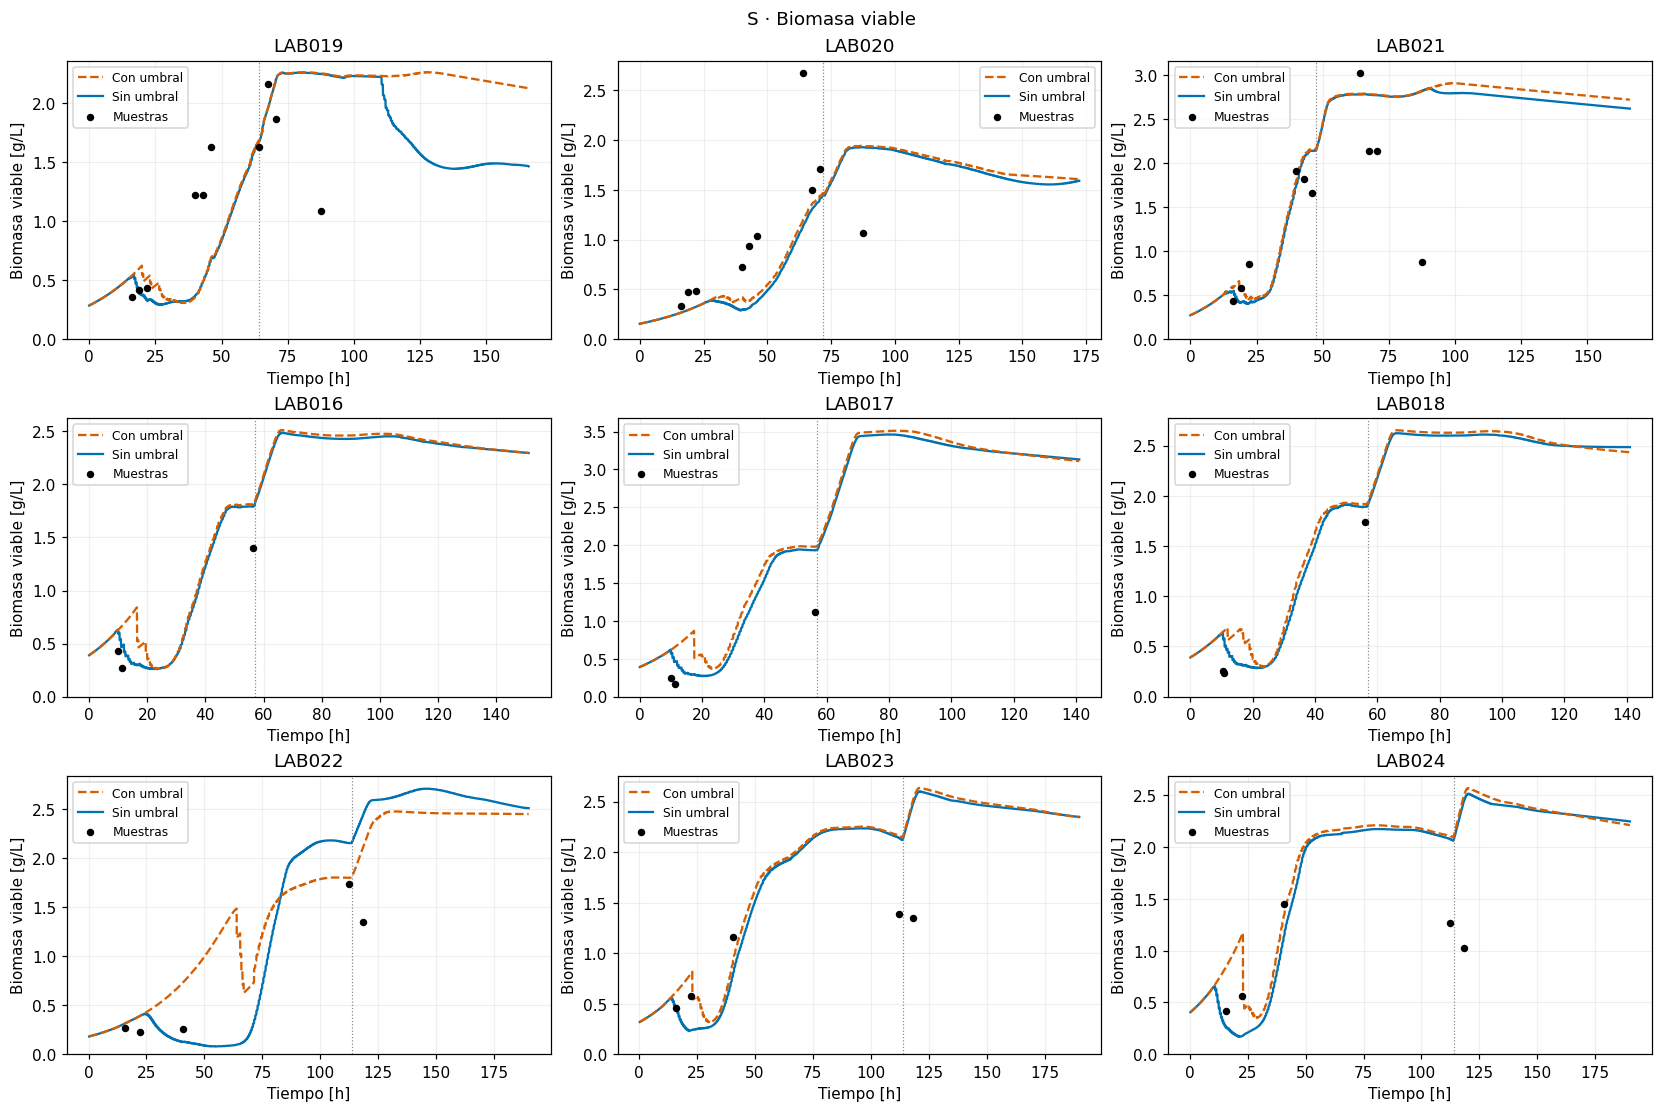

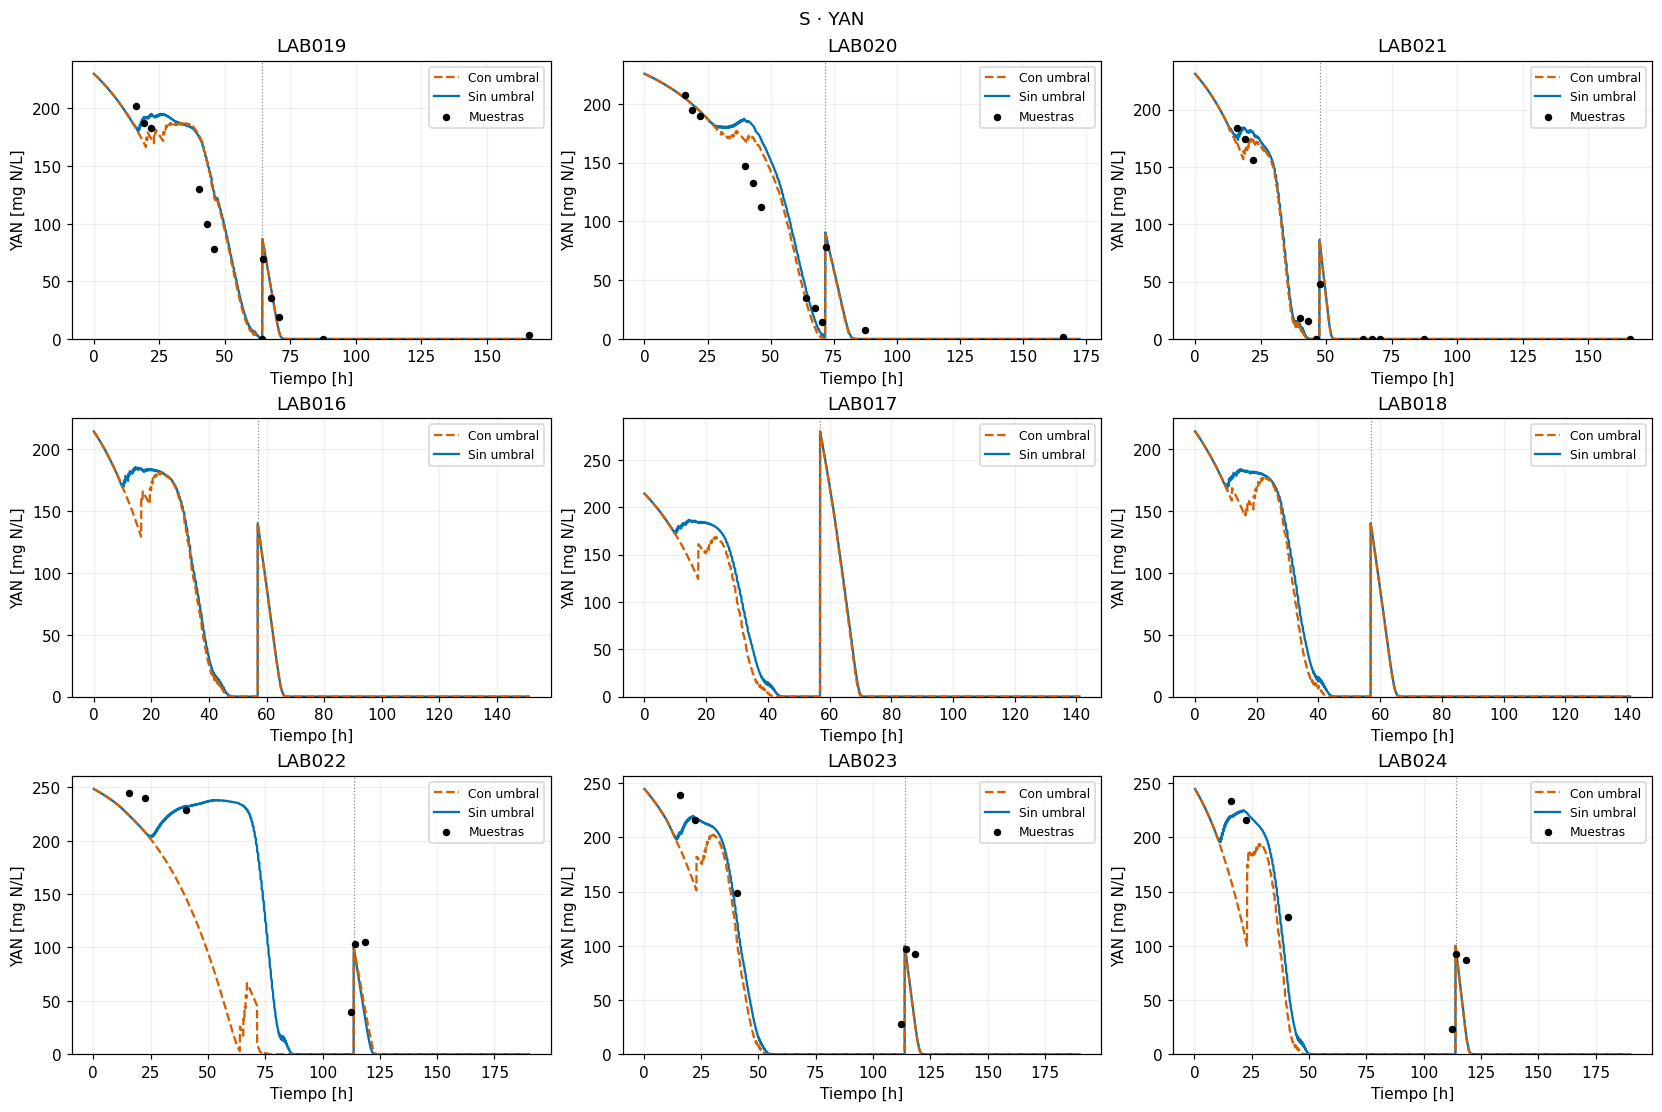

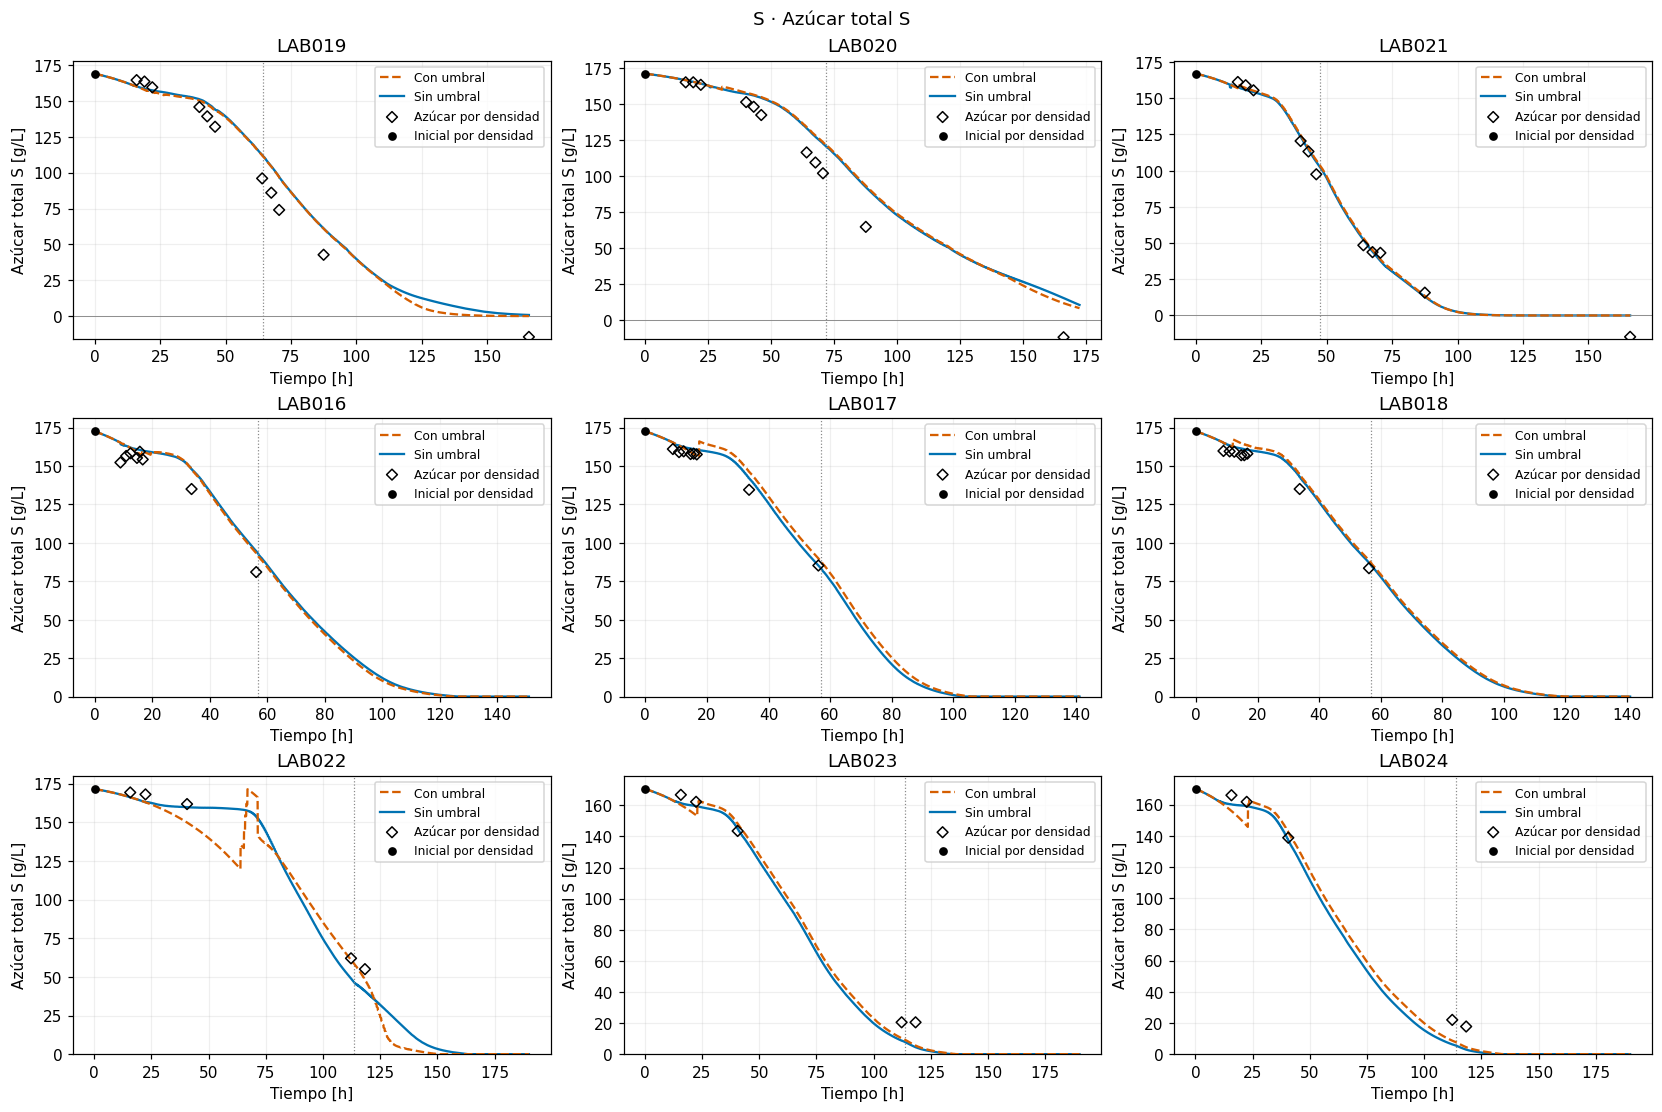

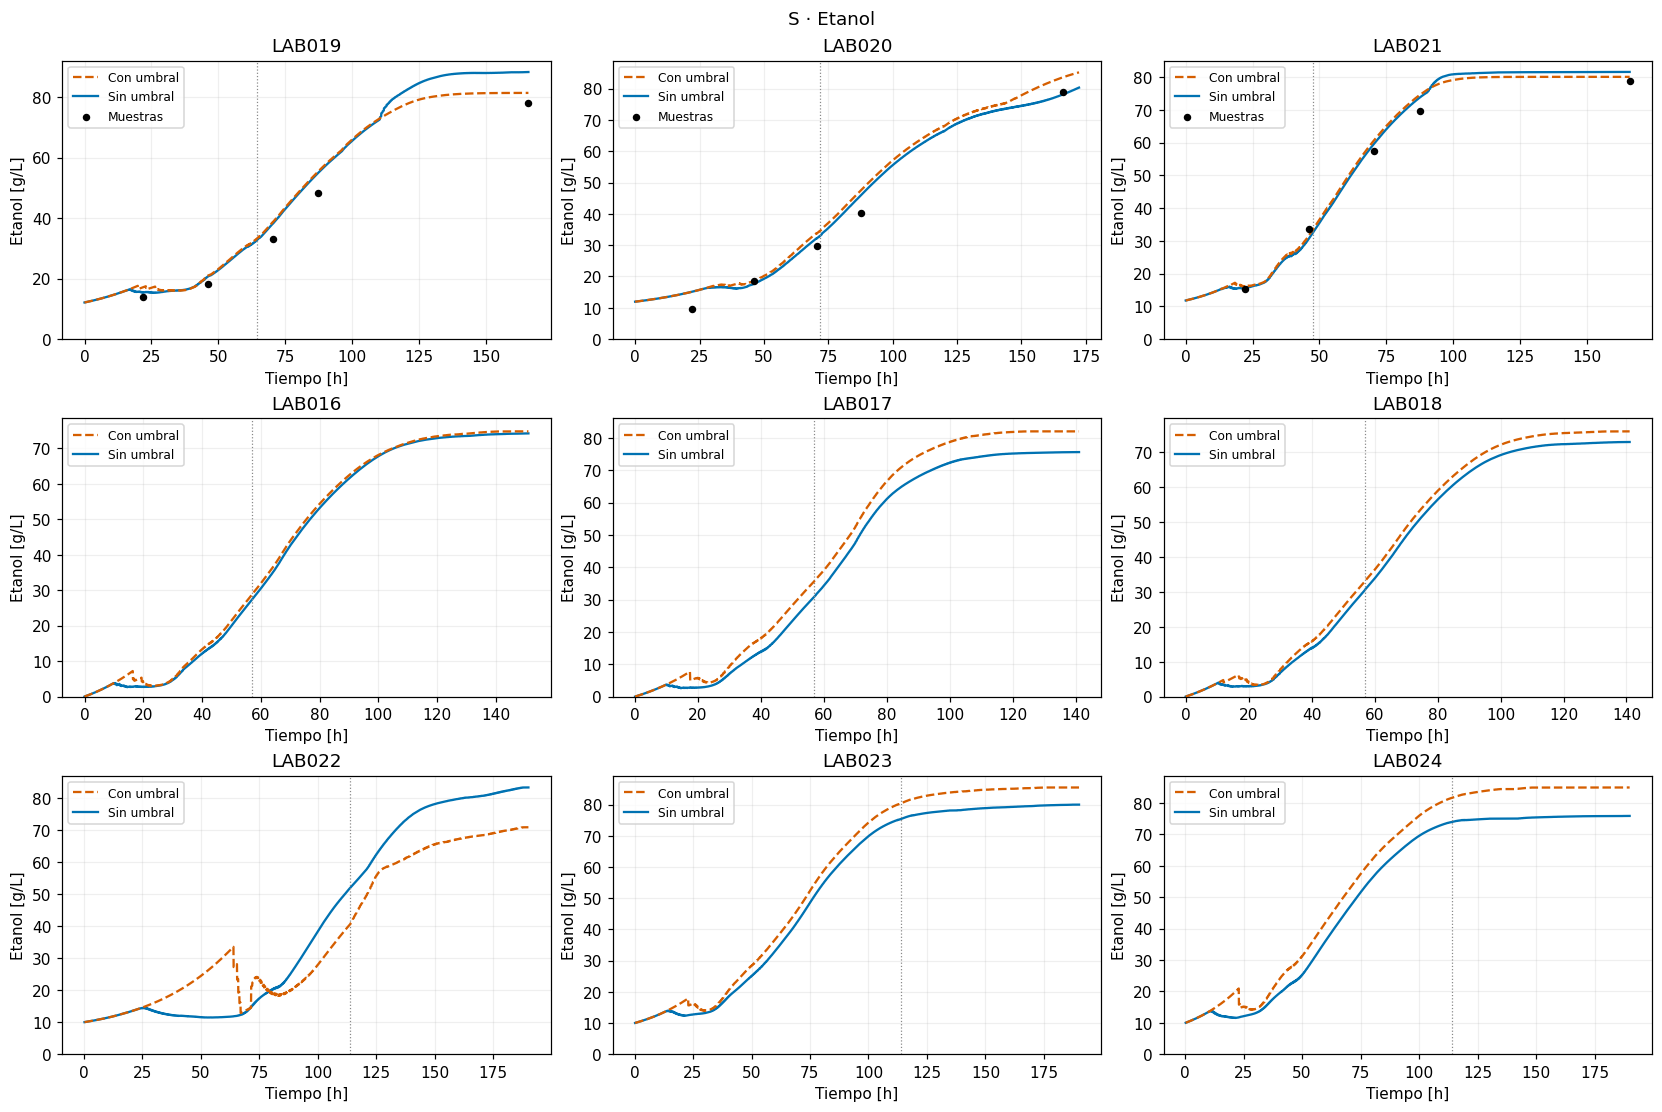

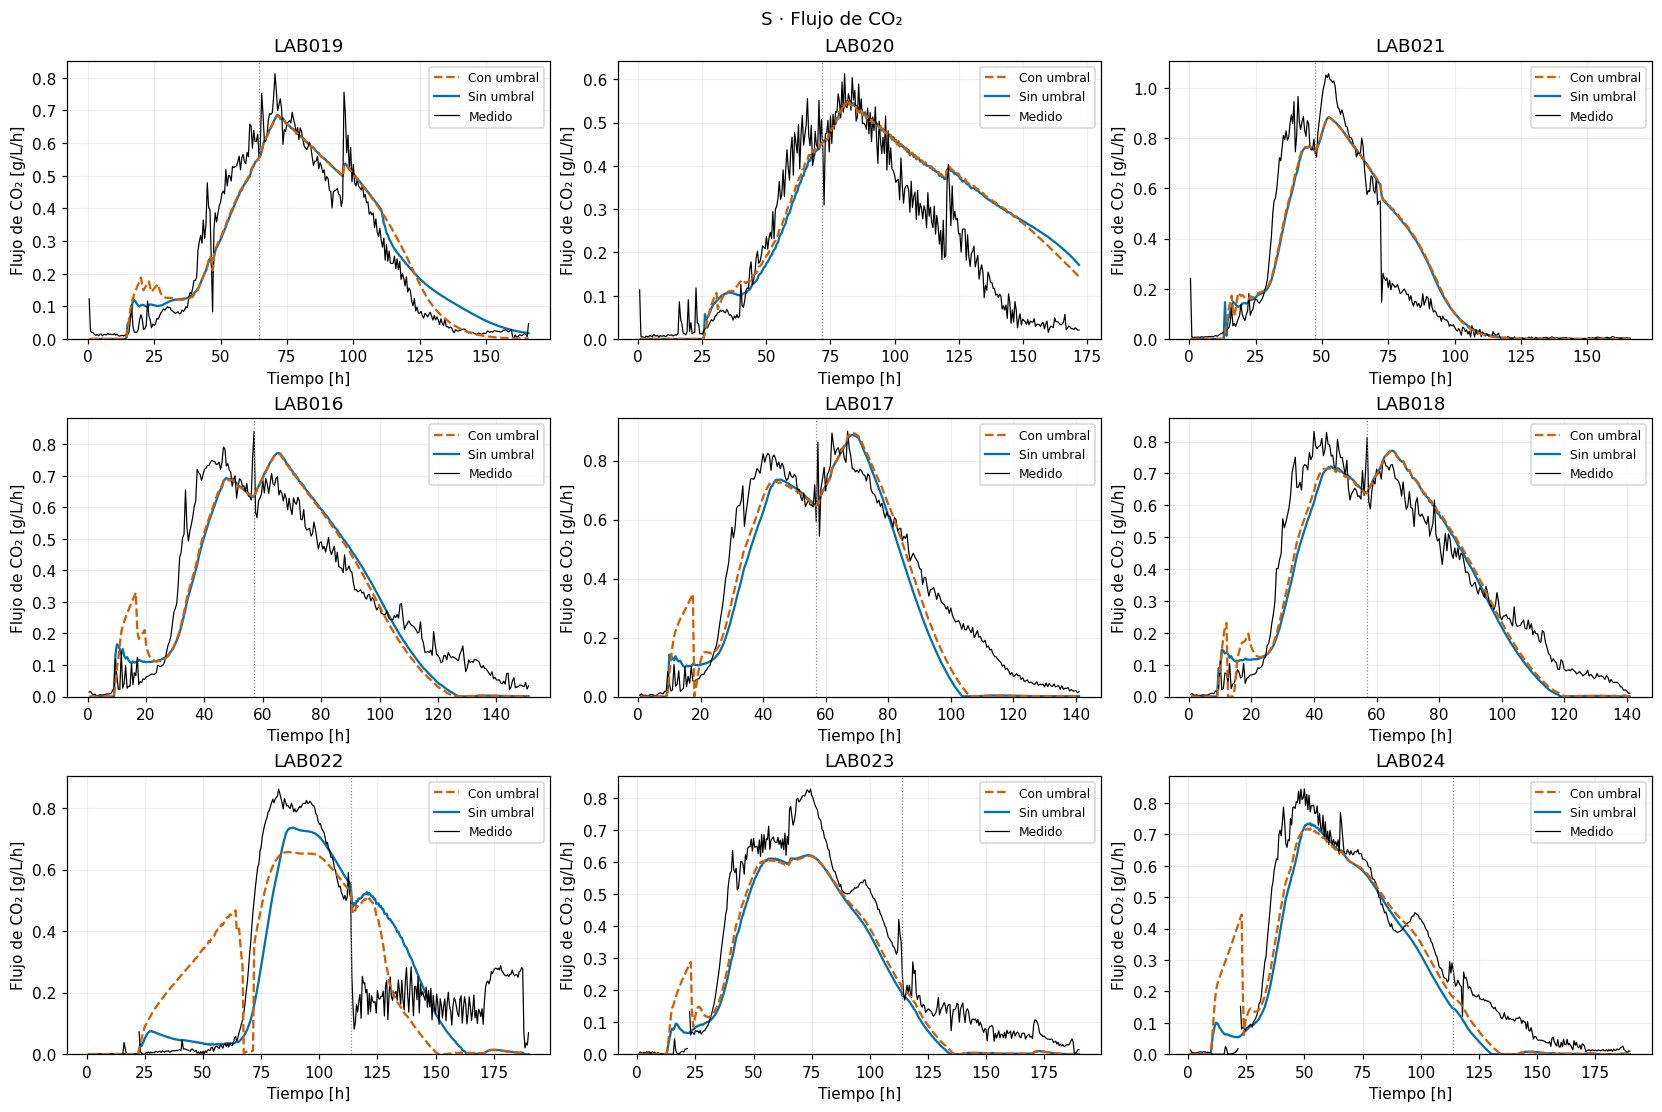

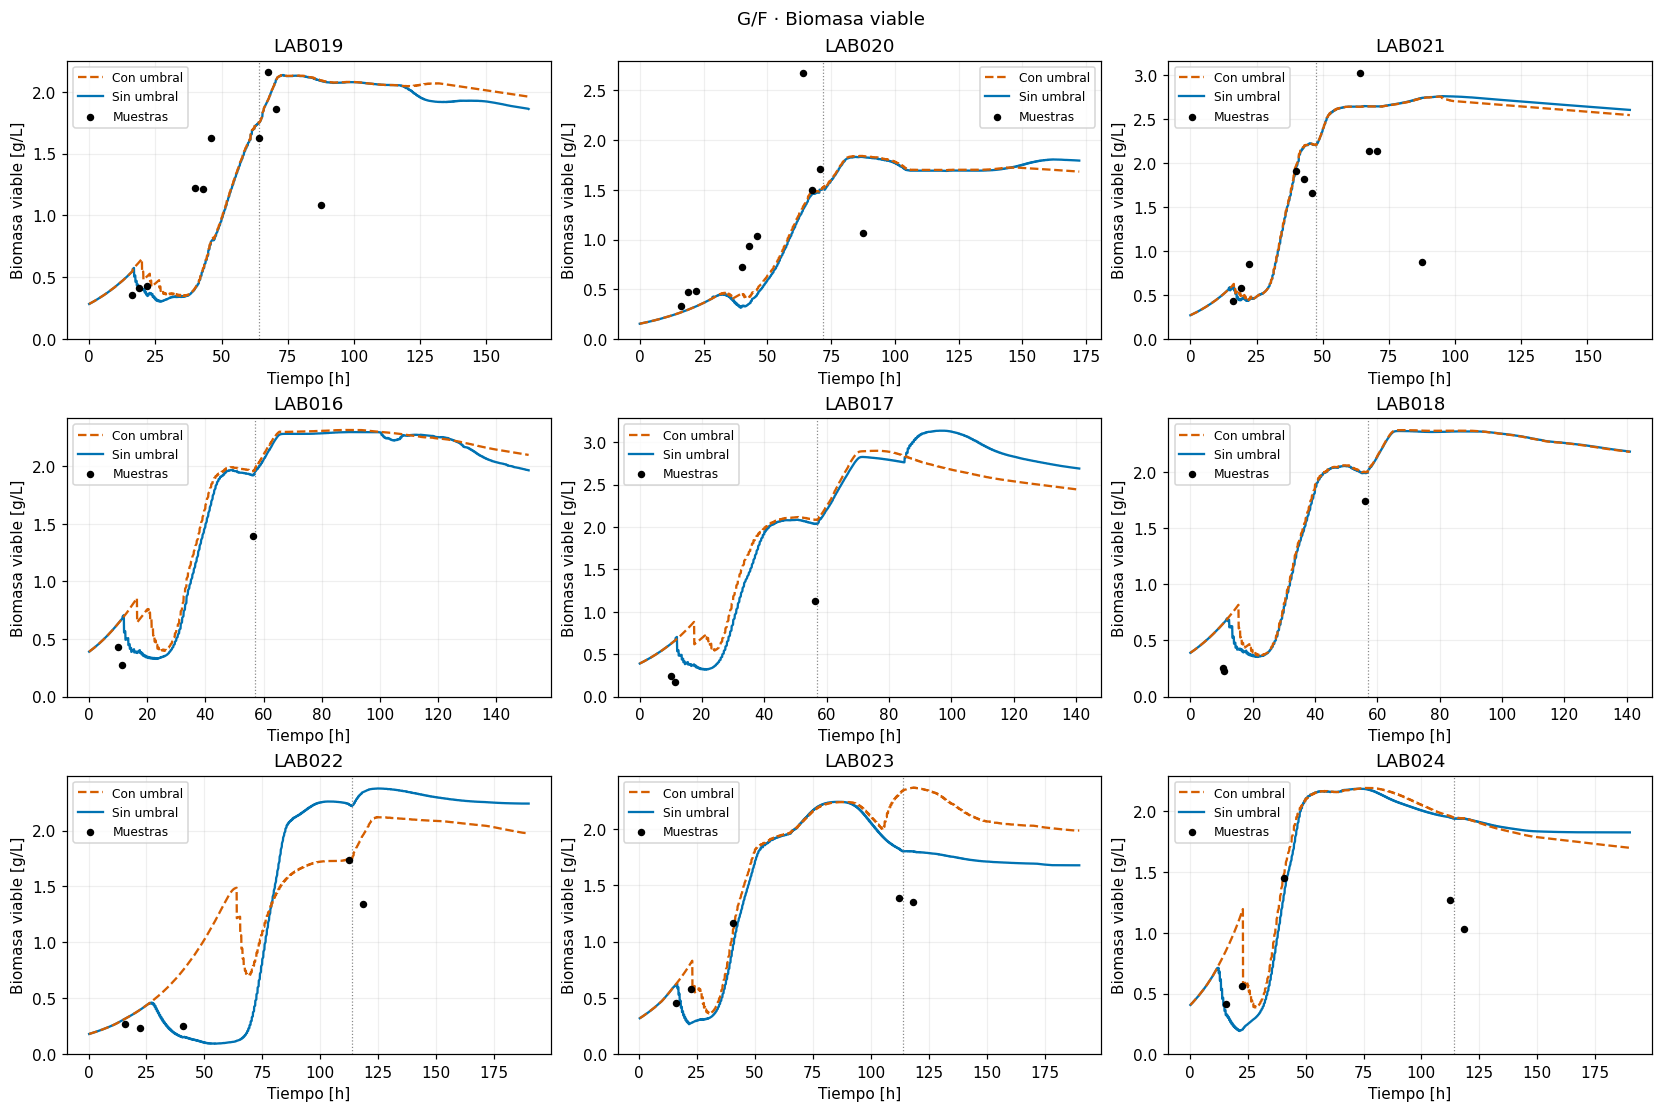

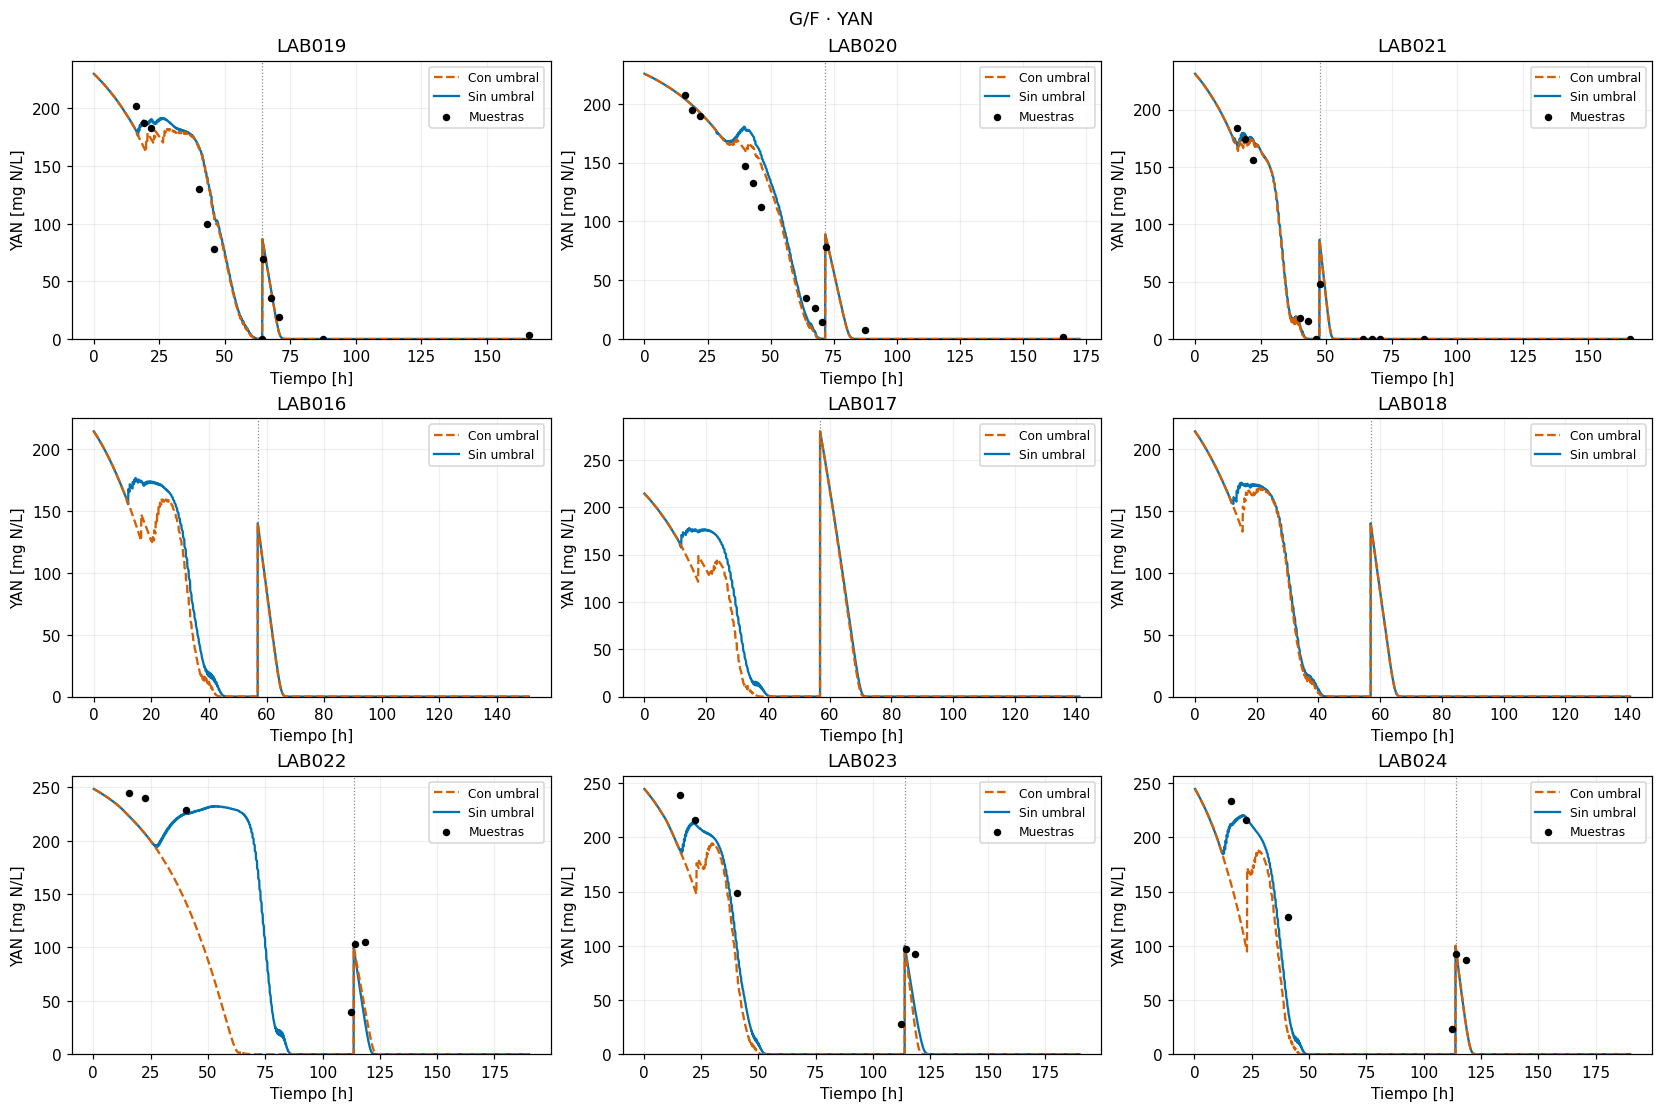

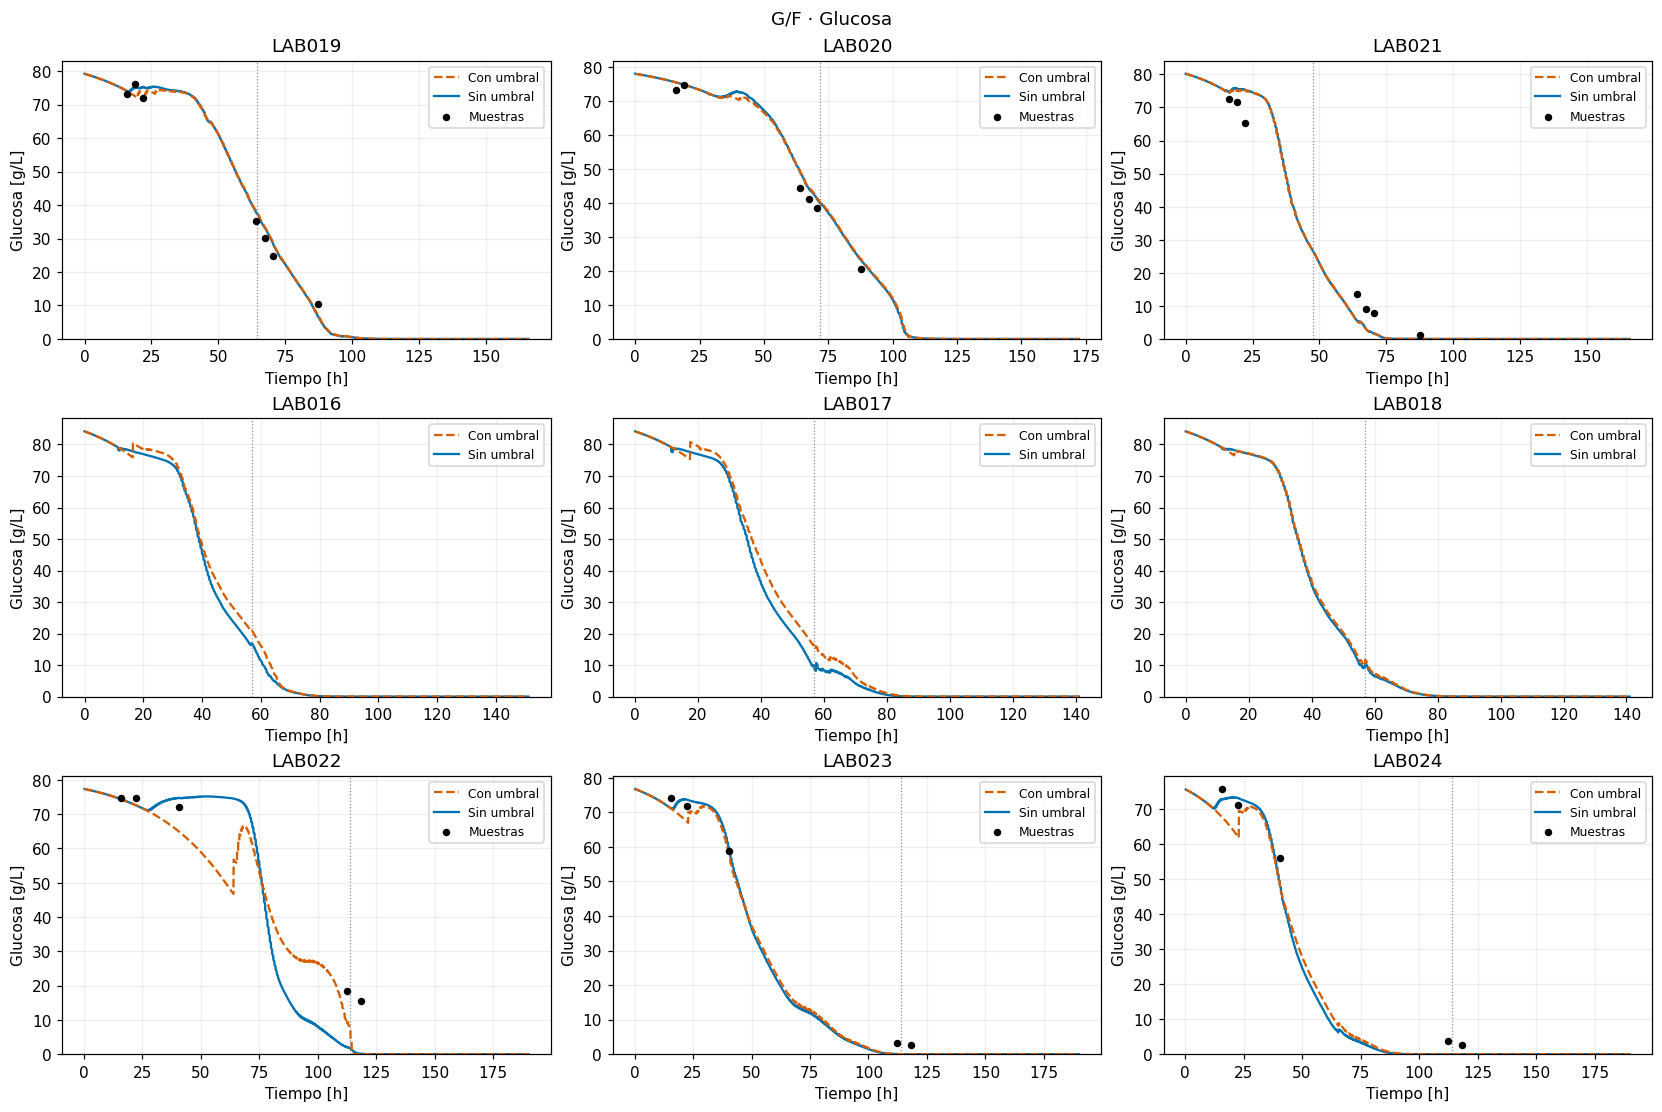

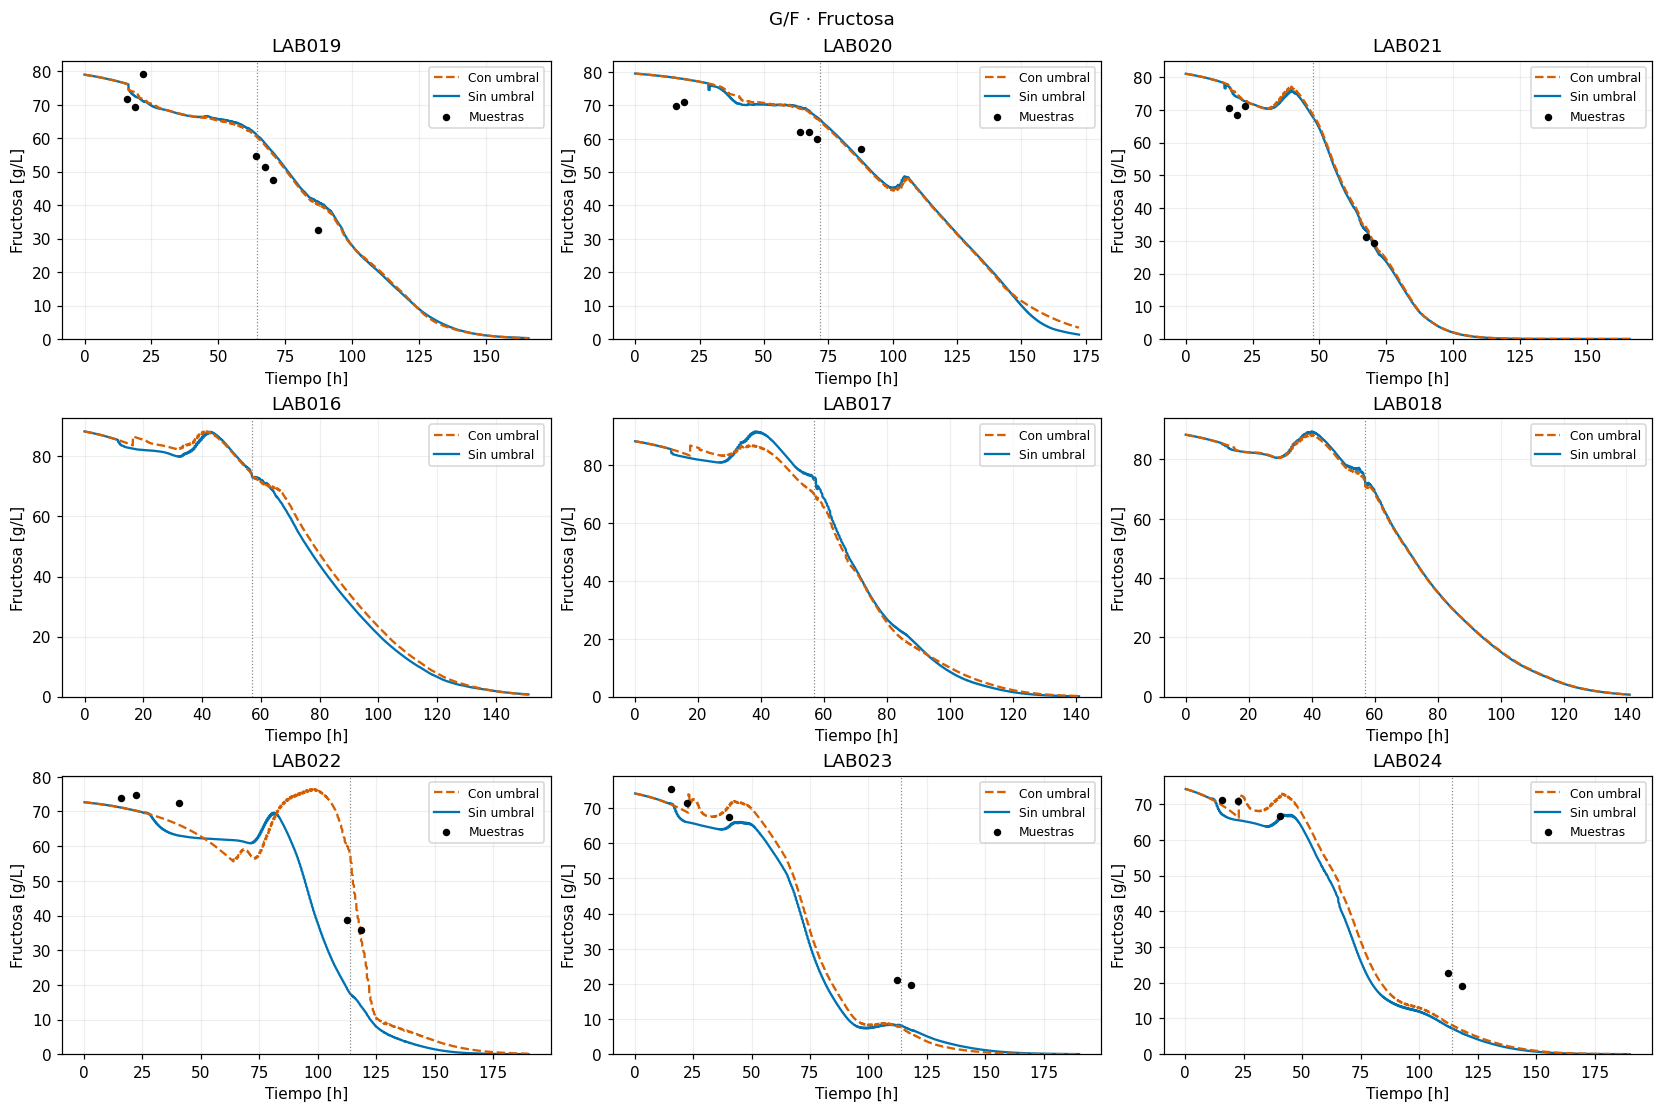

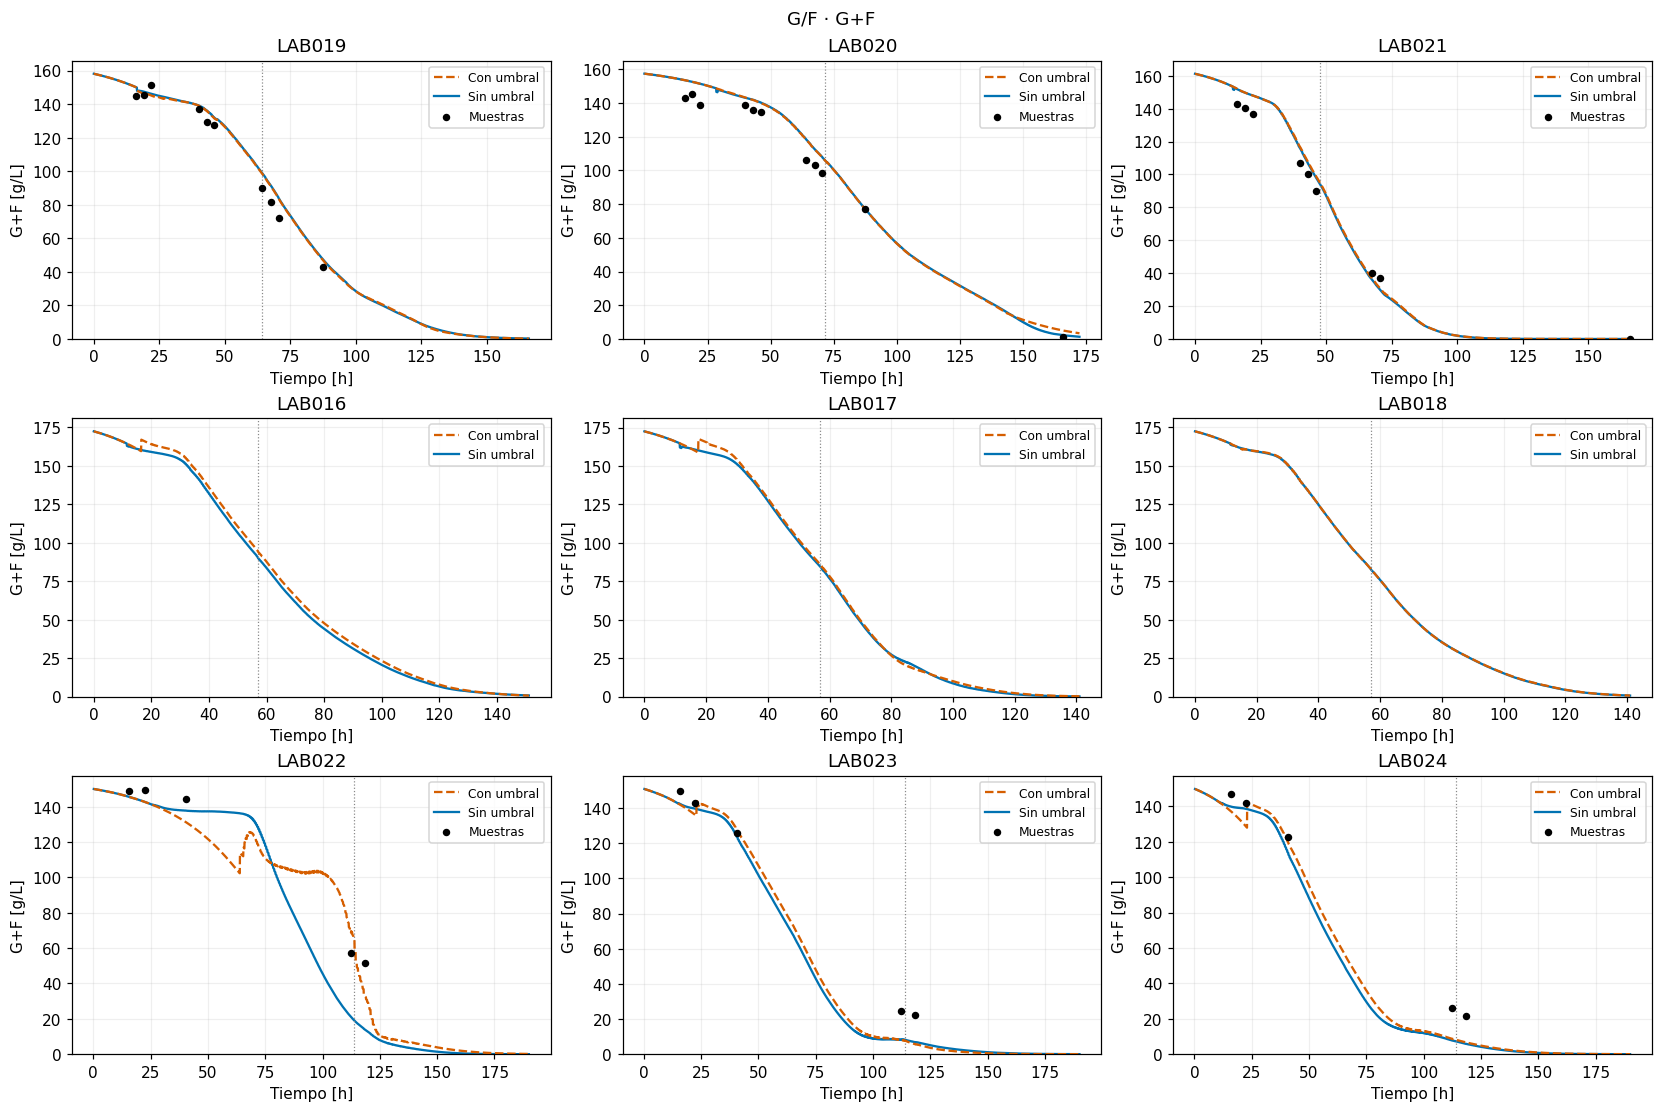

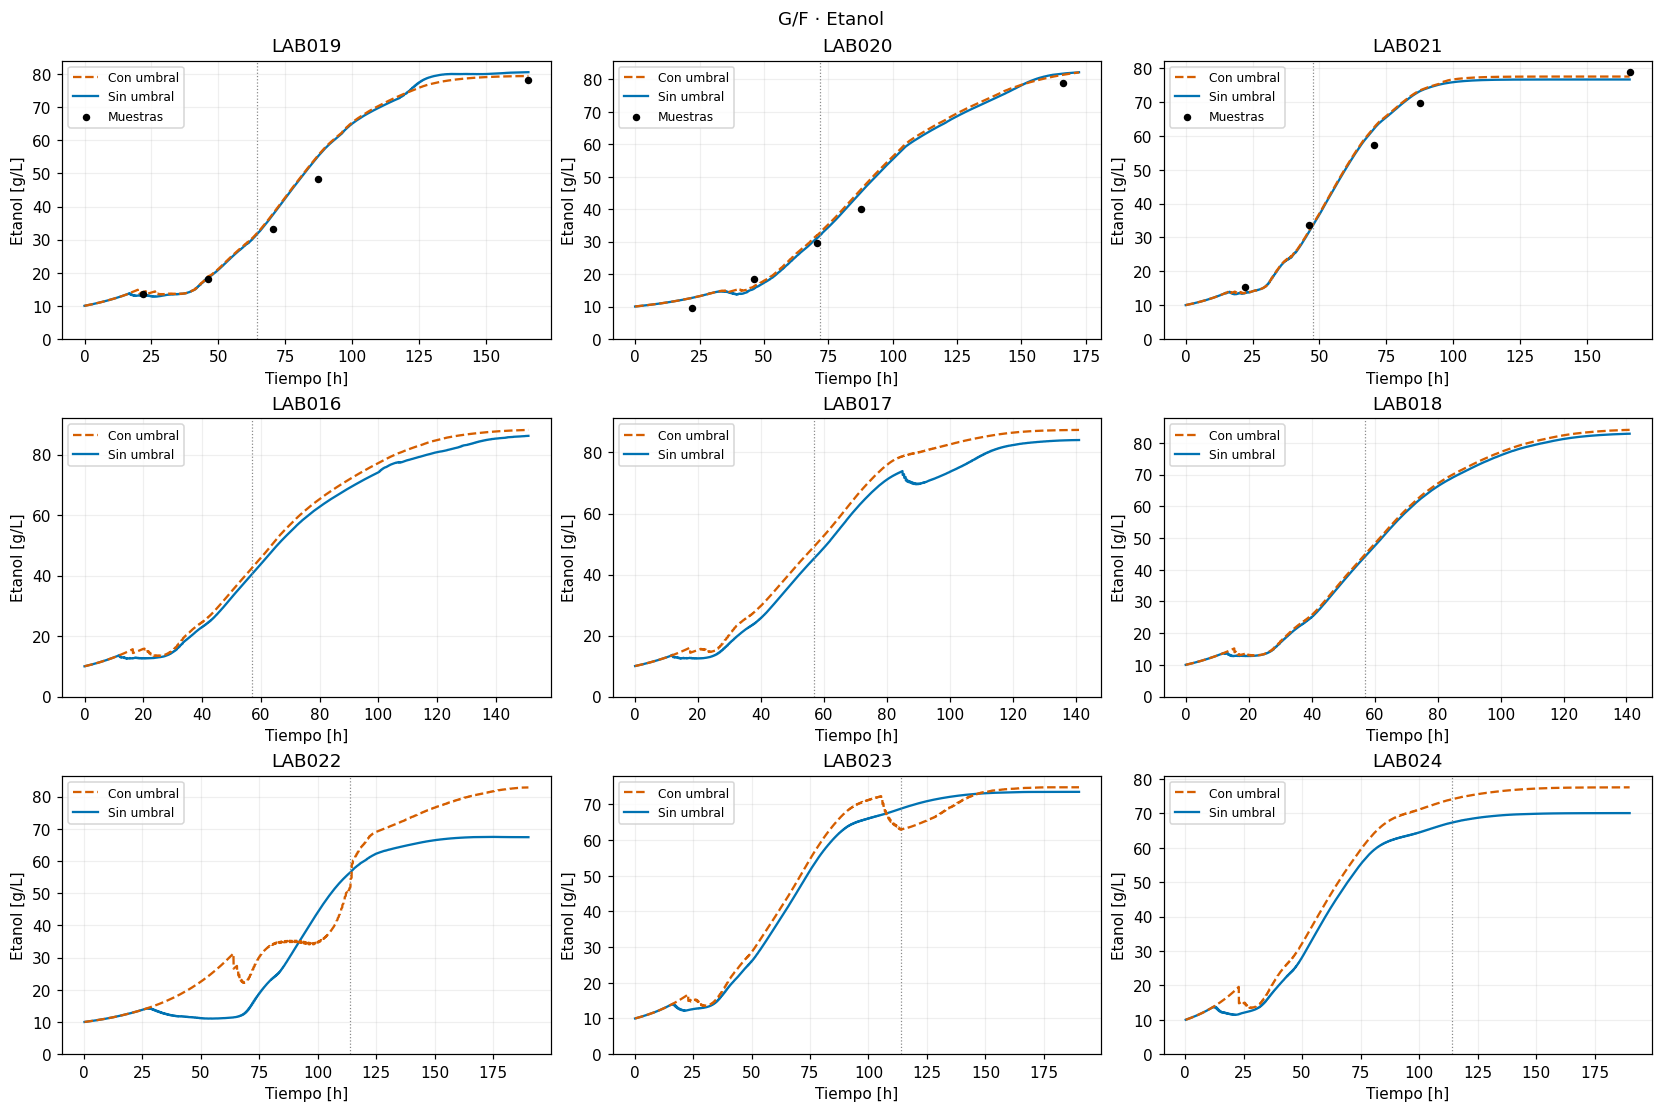

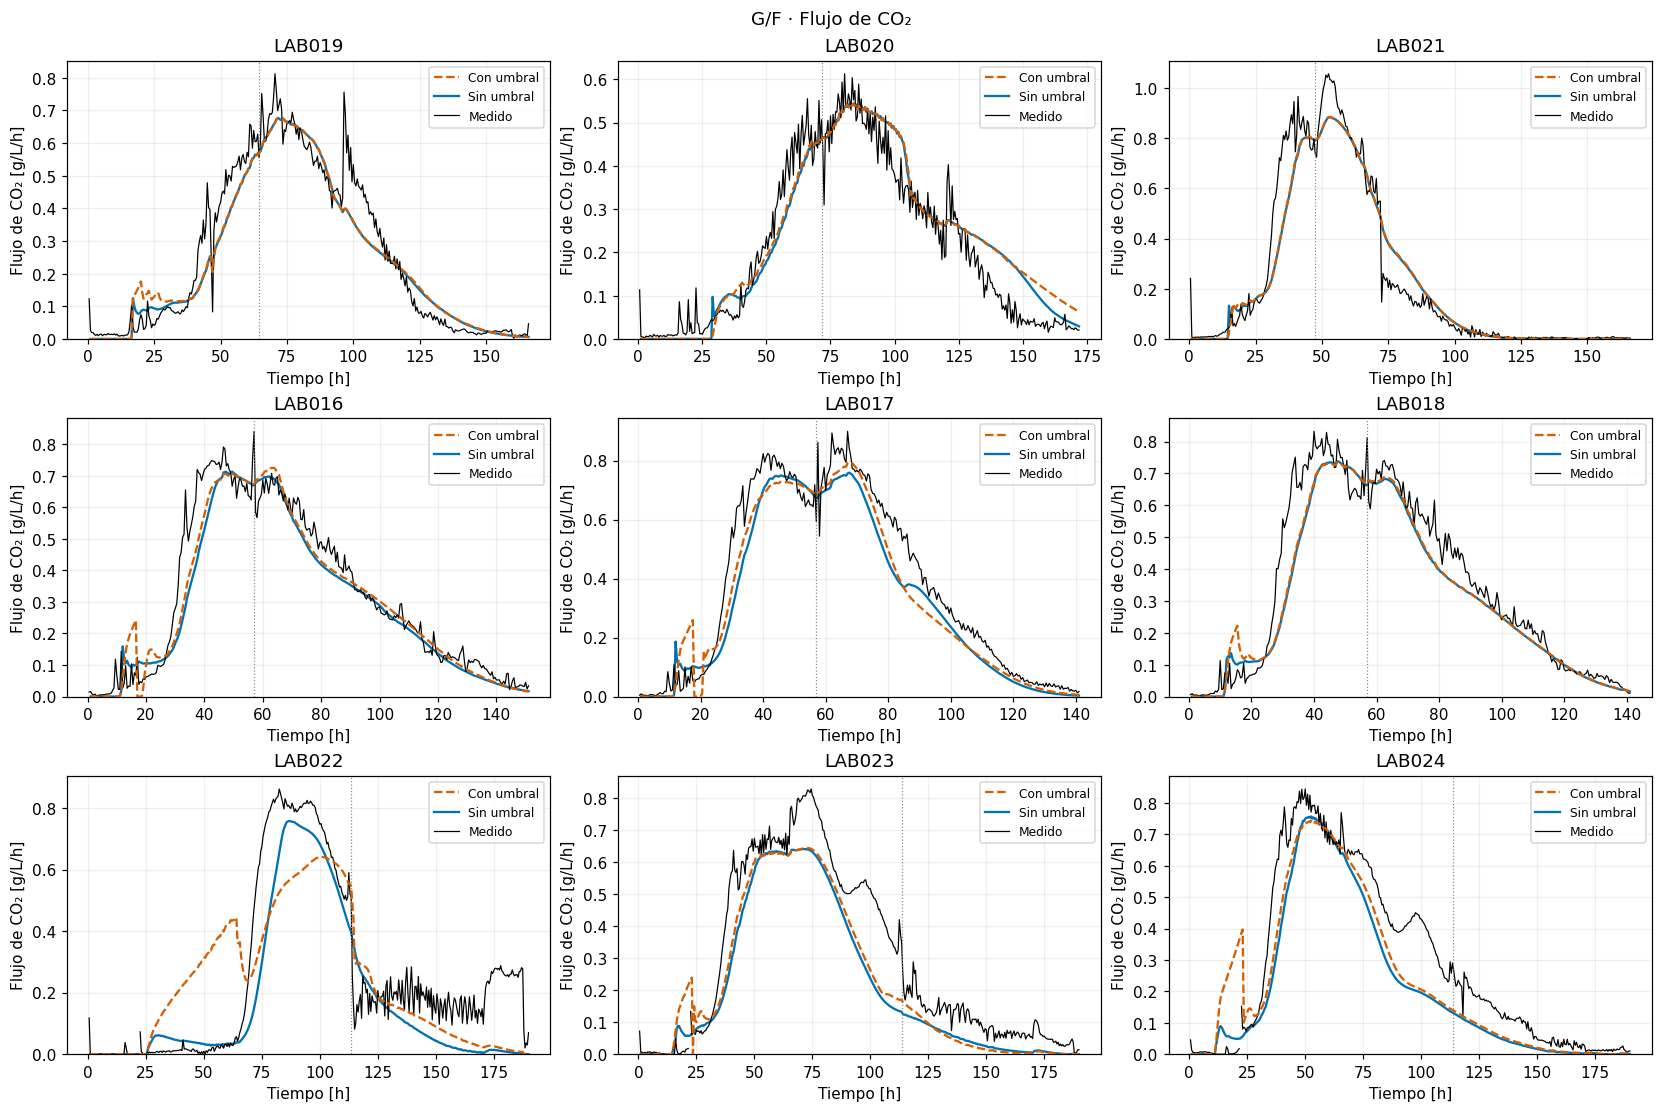

In [6]:
def draw_curves(ax, model, lab, variable, *, legend=True):
    for rule in RULES:
        run = TRAJECTORIES[model, lab, rule]
        if variable == "CO2":
            gas = run["gas"]
            plot = gas.time.ge(1.)
            ax.plot(gas.time[plot], gas.forecast[plot], label=rule, **STYLES[rule])
        else:
            ax.plot(run["time"], run["states"][variable], label=rule, **STYLES[rule])
    if variable == "CO2":
        ax.plot(gas.time, gas.measured.where(gas.valid), c="black", lw=.8, label="Medido")
    else:
        times, values = lab_samples(model, lab, variable)
        if variable == "S":
            density = density_points[lab]
            ax.scatter(times, values, marker="D", facecolors="none", edgecolors="black",
                       s=25, zorder=5, label="Azúcar por densidad")
            ax.scatter(density["initial_time"], density["initial_sugar"], c="black",
                       s=22, zorder=5, label="Inicial por densidad")
        elif len(times):
            ax.scatter(times, values, c="black", s=15, zorder=5, label="Muestras")
    for pulse in run["pulse"]:
        ax.axvline(pulse, c="#888888", ls=":", lw=.8)
    title, unit = SYMBOLS[variable]
    lower = min(0., 1.10 * min(values)) if variable == "S" else 0.
    ax.set(title=lab, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", ylim=(lower, None))
    if lower < 0.:
        ax.axhline(0., c="#888888", lw=.6)
    ax.grid(alpha=.2)
    if legend:
        ax.legend(fontsize=8)


for model, variables in VARIABLES.items():
    for variable in variables:
        fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
        for ax, lab in zip(axes.flat, ORDER):
            draw_curves(ax, model, lab, variable)
        fig.suptitle(f"{model} · {SYMBOLS[variable][0]}")
        plt.show()


## LAB023–024 · ampliaciones del YAN temprano y del flujo de CO₂ tardío

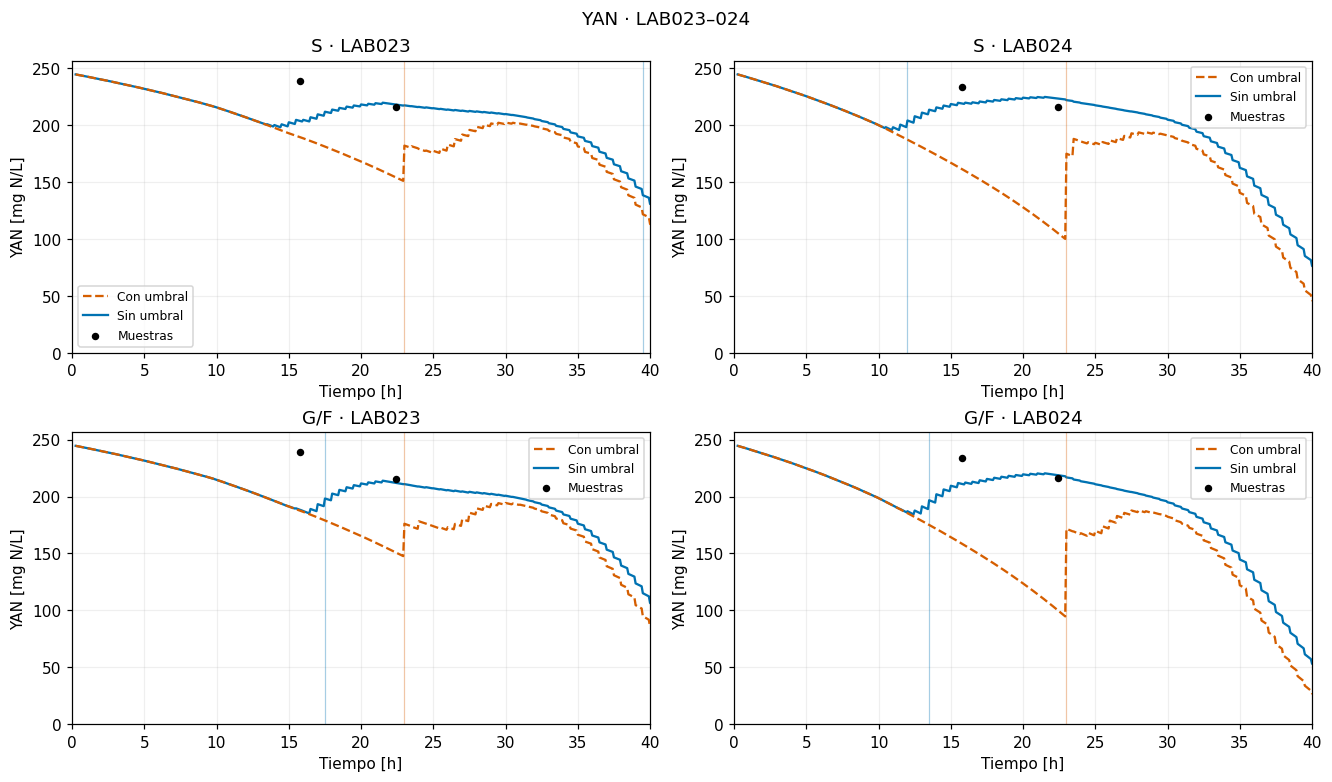

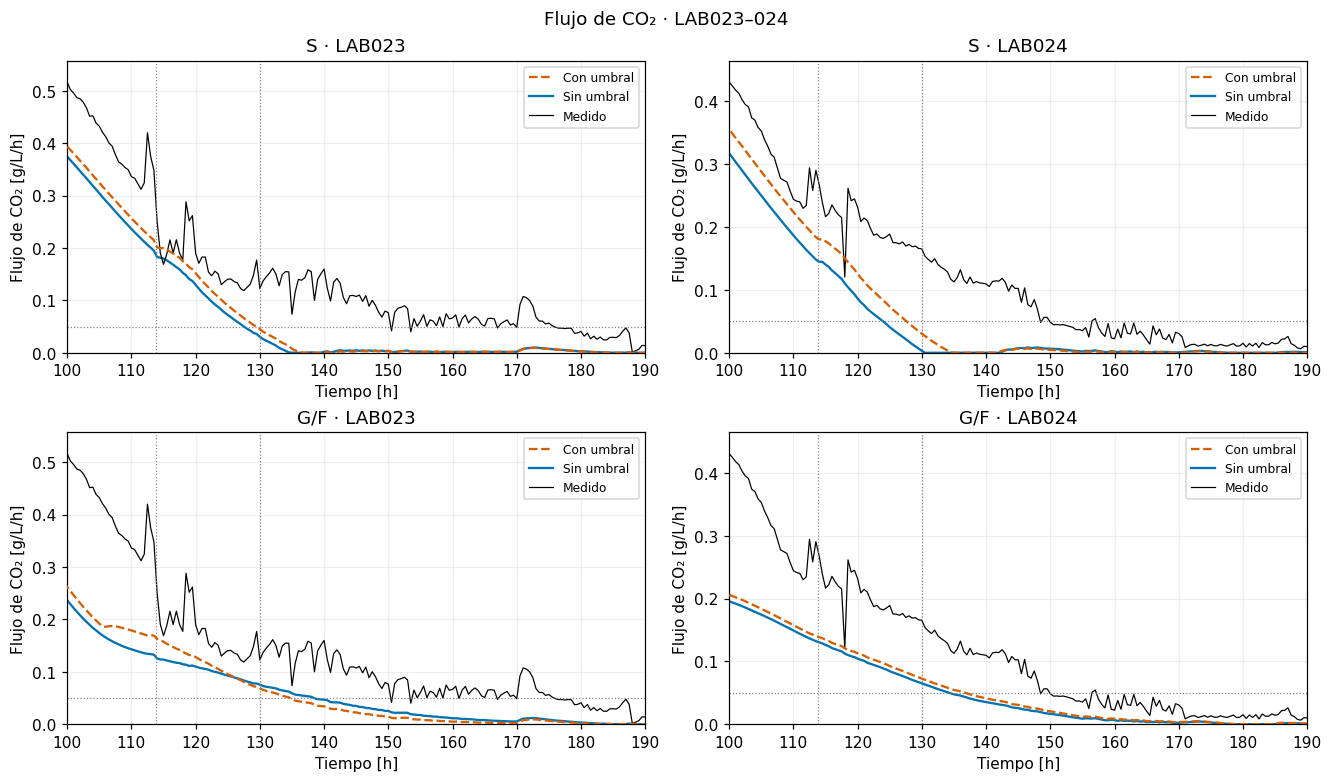

In [7]:
for variable, limits in (("N", (0, 40)), ("CO2", (100, 190))):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for row, model in enumerate(VARIABLES):
        for col, lab in enumerate(FOCUS):
            ax = axes[row, col]
            draw_curves(ax, model, lab, variable)
            ax.set(title=f"{model} · {lab}", xlim=limits)
            if variable == "N":
                for rule in RULES:
                    t = metrics.loc[(model, lab, rule), "Hora del mayor salto [h]"]
                    ax.axvline(t, color=STYLES[rule]["c"], alpha=.35, lw=.8)
            else:
                ax.axhline(.05, c="gray", lw=.8, ls=":")
                ax.axvline(130, c="gray", lw=.8, ls=":")
                top = max(max(gas.loc[gas.time.between(*limits), "forecast"])
                          for rule in RULES for gas in [TRAJECTORIES[model, lab, rule]["gas"]])
                observed = TRAJECTORIES[model, lab, WITH_THRESHOLD]["gas"]
                top = max(top, observed.loc[observed.time.between(*limits), "measured"].max())
                ax.set_ylim(0, 1.08 * top)
    fig.suptitle(f"{SYMBOLS[variable][0]} · LAB023–024")
    plt.show()
